# Week 10 progress check: first steps of Huffman and LZW coding

**INF605 Digital Image Processing, Group 8.** Paper 8: Huffman coding (Huffman, 1952) and LZW coding (Welch, 1984). This notebook is **preliminary work**. It shows that our test images load and that the first steps of both methods run.

**What this notebook does**

1. Loads the test images (real SIPI images plus two synthetic ones) as 8-bit grayscale.
2. Computes each image's histogram, probabilities and **entropy**.
3. Measures two baselines: the raw size (8 bits per pixel) and the **PNG** size (`cv2.imencode`, comparison only).
4. Builds Huffman codes **with our own code** and checks them against the paper's example (average length 3.42).
5. Runs a first, partial version of the **LZW encoder** (encoder only).

**What it does not do yet** (this is the plan for Weeks 11 to 14): bit packing into real bytes, the code table or header cost, the Huffman decoder, the LZW decoder, variable code widths, and the experiments.

**Library rule.** No library function that implements Huffman or LZW is used. `cv2.imencode` (PNG) is used only to compare results. `cv2` is also used to read images and convert colour to gray.

## 0. Setup

In [3]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 110

## 1. Load the test images

The images come from the [USC-SIPI Image Database](https://sipi.usc.edu/database/) and are stored in the repository folder `images/`. Two of the six are in colour (4.2.01 and 4.2.03). We convert colour images to gray with OpenCV's standard luminance conversion, because the project works on grayscale images.

We also generate two **synthetic** images with NumPy. They are extreme cases that help us understand the methods:

- **stripes**: a repeating pattern with only two gray values (very easy to compress).
- **noise**: random pixel values (impossible to compress).

The path handling below works whether the notebook is started from `notebooks/` or from the repository root.

In [4]:
IMAGE_DIR = next(p for p in ("../images", "images") if os.path.isdir(p))
FIG_DIR = os.path.join(os.path.dirname(IMAGE_DIR), "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# name shown in tables -> file in images/   (short description from looking at the image)
REAL_IMAGES = {
    "5.1.09 moon":      "5.1.09.tiff",        # moon surface, 256x256, gray
    "7.1.10 desert":    "7.1.10.tiff",        # desert scene with cars, 512x512, gray
    "5.3.01 portrait":  "5.3.01.tiff",        # portrait, 1024x1024, gray
    "4.2.01 milk drop": "4.2.01.tiff",        # milk drop, 512x512, colour
    "4.2.03 mandrill":  "4.2.03.tiff",        # mandrill, 512x512, colour
    "texmos1 textures": "texmos1.p512.tiff",  # texture mosaic, 512x512, gray
}

def load_gray(path):
    """Read an image file and return (8-bit gray array, was_colour)."""
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise FileNotFoundError(path)
    was_colour = img.ndim == 3
    if was_colour:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # OpenCV reads colour as BGR
    assert img.dtype == np.uint8 and img.ndim == 2
    return img, was_colour

images, source = {}, {}
for name, fname in REAL_IMAGES.items():
    images[name], was_colour = load_gray(os.path.join(IMAGE_DIR, fname))
    source[name] = "USC-SIPI, colour converted to gray" if was_colour else "USC-SIPI, gray"

# synthetic images (fixed seed so every run gives the same noise)
rng = np.random.default_rng(0)
_, xx = np.mgrid[0:256, 0:256]
images["synthetic stripes"] = (((xx // 8) % 2) * 200 + 28).astype(np.uint8)
images["synthetic noise"] = rng.integers(0, 256, (256, 256), dtype=np.uint8)
source["synthetic stripes"] = source["synthetic noise"] = "generated with NumPy"

info = pd.DataFrame({
    "size": [f"{im.shape[1]}x{im.shape[0]}" for im in images.values()],
    "pixels": [im.size for im in images.values()],
    "dtype": [str(im.dtype) for im in images.values()],
    "source": list(source.values()),
}, index=list(images))
info

,size,pixels,dtype,source
5.1.09 moon,256x256,65536,uint8,"USC-SIPI, gray"
7.1.10 desert,512x512,262144,uint8,"USC-SIPI, gray"
5.3.01 portrait,1024x1024,1048576,uint8,"USC-SIPI, gray"
4.2.01 milk drop,512x512,262144,uint8,"USC-SIPI, colour converted to gray"
4.2.03 mandrill,512x512,262144,uint8,"USC-SIPI, colour converted to gray"
texmos1 textures,512x512,262144,uint8,"USC-SIPI, gray"
synthetic stripes,256x256,65536,uint8,generated with NumPy
synthetic noise,256x256,65536,uint8,generated with NumPy


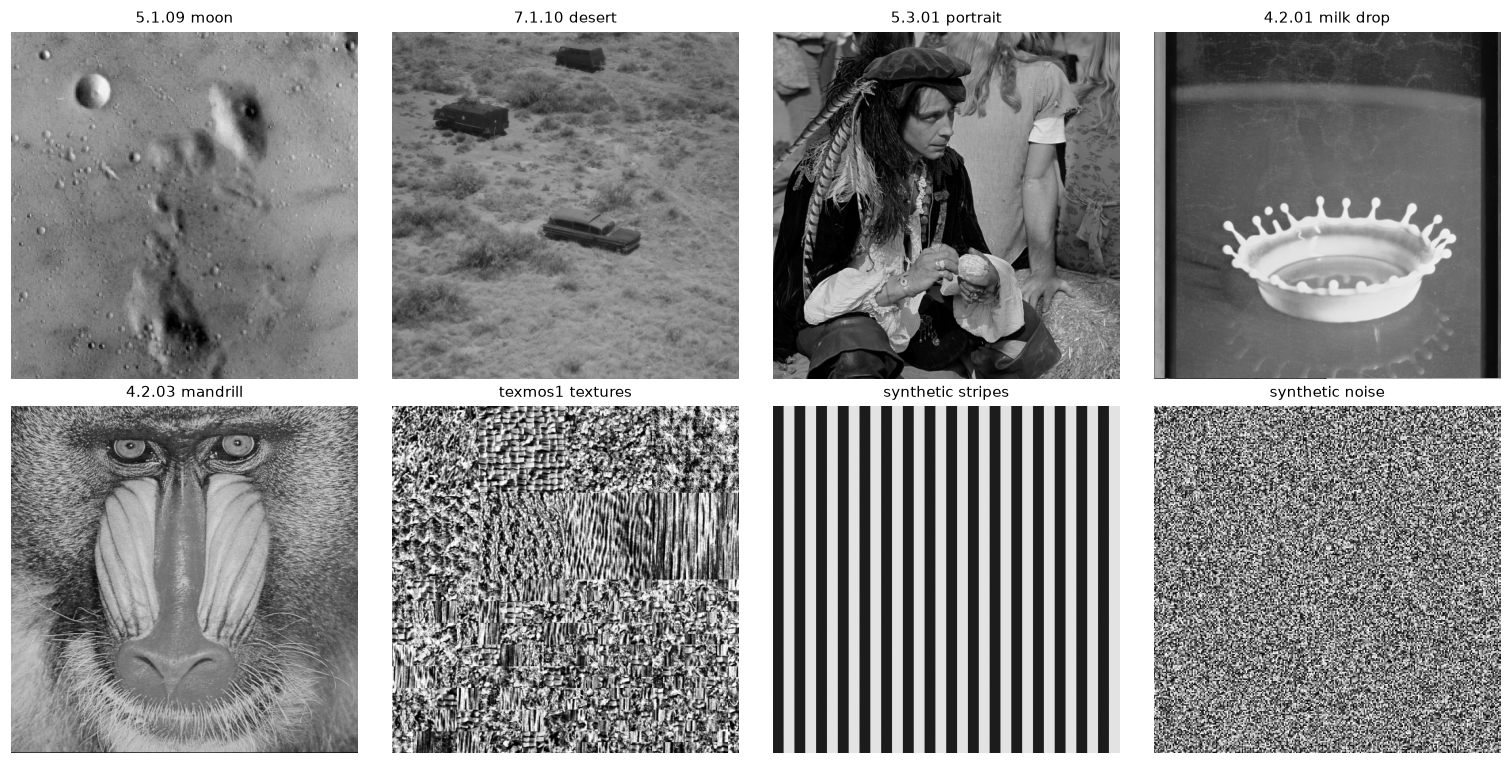

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (name, img) in zip(axes.ravel(), images.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "images_overview.png"), bbox_inches="tight")
plt.show()

## 2. First step of the method: histogram, probabilities and entropy

Both papers start from the same observation: some symbols are more common than others. For an image, the symbols are the pixel values 0 to 255. We count how often each value occurs (the **histogram**) and divide by the number of pixels to get probabilities $p_i$.

**Entropy** is the average information per symbol, in bits. It is the lowest average code length that any lossless code can reach when it codes one pixel at a time:

$$H = -\sum_i p_i \log_2 p_i$$

Terms with $p_i = 0$ are skipped (they contribute nothing).

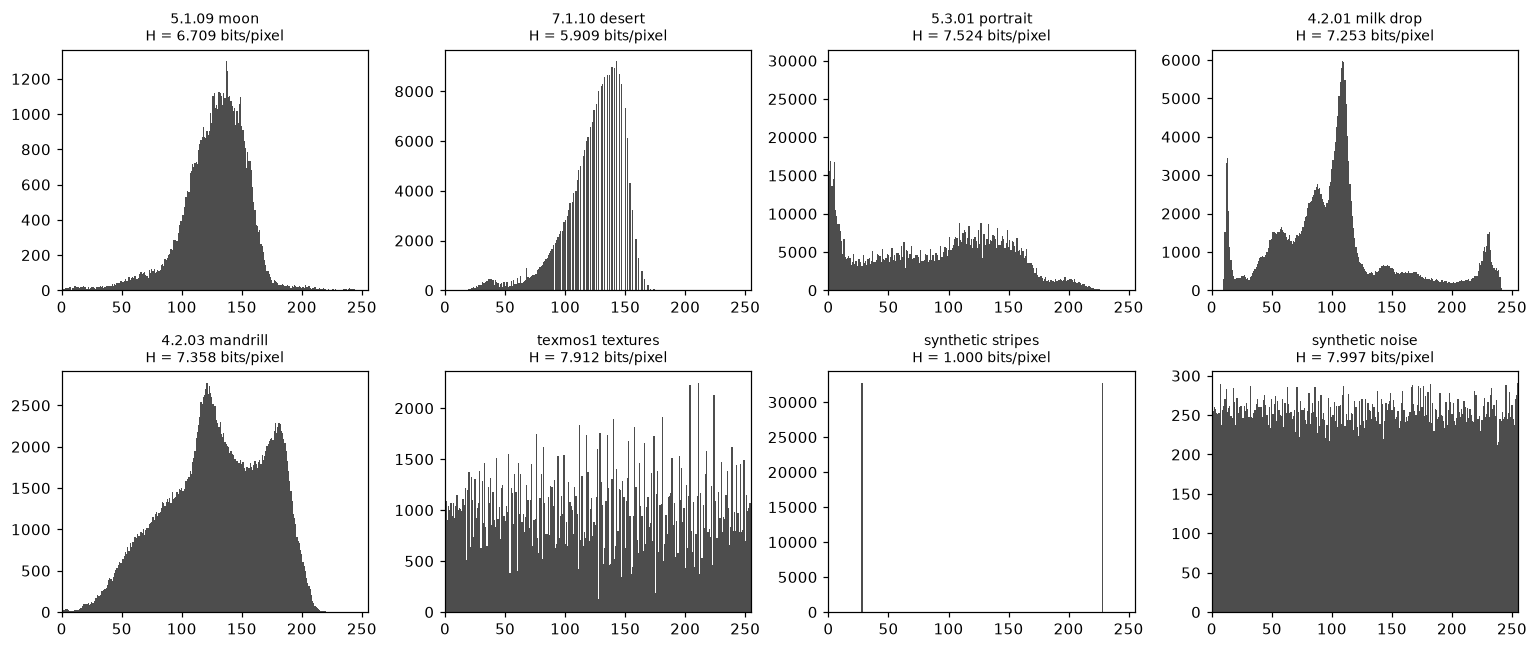

In [6]:
def histogram(img):
    """Number of pixels for each gray value 0..255."""
    return np.bincount(img.ravel(), minlength=256)

def entropy_bits(counts):
    """Entropy H in bits per symbol, from a vector of counts."""
    p = counts[counts > 0] / counts.sum()
    return float(-(p * np.log2(p)).sum())

results = {name: {} for name in images}
for name, img in images.items():
    results[name]["H"] = entropy_bits(histogram(img))

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharey=False)
for ax, (name, img) in zip(axes.ravel(), images.items()):
    ax.bar(range(256), histogram(img), width=1.0, color="0.3")
    ax.set_title(f"{name}\nH = {results[name]['H']:.3f} bits/pixel", fontsize=9)
    ax.set_xlim(0, 255)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "histograms.png"), bbox_inches="tight")
plt.show()

## 3. Baselines: raw size and PNG

- **Raw:** 8 bits per pixel.
- **PNG:** the image saved as PNG at the highest compression level (`cv2.imencode`). This is for **comparison only**. We are not allowed to use library functions that implement our methods.

We express every size in **bits per pixel (bpp)**. The compression ratio is 8 divided by the bpp.

In [7]:
def png_bits_per_pixel(img):
    ok, buf = cv2.imencode(".png", img, [cv2.IMWRITE_PNG_COMPRESSION, 9])
    assert ok
    return buf.size * 8 / img.size

for name, img in images.items():
    results[name]["PNG"] = png_bits_per_pixel(img)

pd.DataFrame({k: {"entropy H": v["H"], "PNG": v["PNG"]} for k, v in results.items()}).T.round(3)

,entropy H,PNG
5.1.09 moon,6.709,5.496
7.1.10 desert,5.909,5.135
5.3.01 portrait,7.524,5.364
4.2.01 milk drop,7.253,4.378
4.2.03 mandrill,7.358,6.363
texmos1 textures,7.912,7.255
synthetic stripes,1.000,0.047
synthetic noise,7.997,8.054


## 4. Second step: building Huffman codes

Huffman's recipe (his 1952 paper):

1. List the symbols with their probabilities (or counts).
2. Merge the two least probable symbols into one combined symbol. Its weight is the sum of the two.
3. Repeat until one symbol is left. The merges form a binary tree.
4. Walk down the tree, writing 0 for one branch and 1 for the other. A symbol's code is the path to it.

The quantity Huffman minimises is the **average code length**:

$$L_{av} = \sum_i P(i)\, L(i)$$

Our implementation keeps a plain list and sorts it at every step. With at most 256 symbols this is fast enough, and it keeps the code short and easy to read. Ties are broken by creation order, so the result is always the same.

In [8]:
def huffman_codes(counts):
    """Build a Huffman code. counts: dict symbol -> weight (> 0).
    Returns dict symbol -> code as a string of '0' and '1'."""
    # a node is (weight, order, payload); payload is ("leaf", symbol) or ("node", left, right)
    nodes = [(w, i, ("leaf", s)) for i, (s, w) in enumerate(sorted(counts.items()))]
    if len(nodes) == 1:                       # constant image: one symbol still needs 1 bit
        return {nodes[0][2][1]: "0"}
    order = len(nodes)
    while len(nodes) > 1:
        nodes.sort(key=lambda n: (n[0], n[1]))        # least probable first
        a, b = nodes[0], nodes[1]
        nodes = nodes[2:] + [(a[0] + b[0], order, ("node", a, b))]
        order += 1

    codes = {}
    def walk(node, prefix):
        payload = node[2]
        if payload[0] == "leaf":
            codes[payload[1]] = prefix
        else:
            walk(payload[1], prefix + "0")
            walk(payload[2], prefix + "1")
    walk(nodes[0], "")
    return codes

def average_length(counts, codes):
    """L_av = sum of weight * code length, divided by the total weight."""
    return sum(w * len(codes[s]) for s, w in counts.items()) / sum(counts.values())

def is_prefix_free(codes):
    """True if no code is the beginning of another code."""
    ordered = sorted(codes.values())
    return all(not b.startswith(a) for a, b in zip(ordered, ordered[1:]))

### Check against the paper

Huffman's own example (his Tables I and II) has 13 messages with these probabilities (in percent): 20, 18, 10, 10, 10, 6, 6, 4, 4, 4, 4, 3, 1. He reports an average length of **3.42**. We use whole numbers (percent) as weights to avoid rounding issues.

Individual code lengths can differ from his table, because several symbols have equal probability and Huffman notes that ties can be broken in any way. The average must be identical.

In [9]:
paper_weights = [20, 18, 10, 10, 10, 6, 6, 4, 4, 4, 4, 3, 1]
paper_counts = {i + 1: w for i, w in enumerate(paper_weights)}
paper_codes = huffman_codes(paper_counts)

lav = average_length(paper_counts, paper_codes)
print("Our average length  :", lav)
print("Paper (Table II)    : 3.42")
print("Our code lengths    :", [len(paper_codes[i + 1]) for i in range(13)])
print("Paper code lengths  :", [2, 3, 3, 3, 3, 4, 5, 5, 5, 5, 5, 6, 6])
print("Prefix-free         :", is_prefix_free(paper_codes))
assert abs(lav - 3.42) < 1e-9 and is_prefix_free(paper_codes)

# the small 5-symbol example from our briefing (hand-checked: L_av = 2.2)
small = {"A": 4, "B": 2, "C": 2, "D": 1, "E": 1}
small_codes = huffman_codes(small)
print("\n5-symbol example    :", small_codes, "-> L_av =", average_length(small, small_codes))
assert abs(average_length(small, small_codes) - 2.2) < 1e-9

Our average length  : 3.42
Paper (Table II)    : 3.42
Our code lengths    : [2, 3, 4, 3, 3, 4, 4, 5, 5, 5, 5, 5, 5]
Paper code lengths  : [2, 3, 3, 3, 3, 4, 5, 5, 5, 5, 5, 6, 6]
Prefix-free         : True

5-symbol example    : {'B': '00', 'C': '01', 'D': '100', 'E': '101', 'A': '11'} -> L_av = 2.2


### Apply it to the images

For each image we build the Huffman code from its histogram and compute the average length. We also check two facts that must always hold:

- the code is prefix-free;
- $H \le L_{av} < H + 1$ (Huffman cannot beat the entropy, and it stays within one bit of it).

**Important:** this number is only the size of the *coded pixels*. It does not include the cost of storing the code table, and it does not yet pack bits into bytes. Both are planned for the next weeks, so real file sizes will be slightly larger.

In [10]:
for name, img in images.items():
    hist = histogram(img)
    counts = {int(s): int(c) for s, c in enumerate(hist) if c > 0}
    codes = huffman_codes(counts)
    lav = average_length(counts, codes)
    H = results[name]["H"]
    assert is_prefix_free(codes)
    assert H <= lav < H + 1 + 1e-9
    results[name]["Huffman"] = lav
    results[name]["n_symbols"] = len(counts)
    results[name]["longest_code"] = max(len(c) for c in codes.values())

huff_table = pd.DataFrame({k: {"symbols used": v["n_symbols"], "longest code (bits)": v["longest_code"],
                               "H": v["H"], "Huffman L_av": v["Huffman"],
                               "L_av - H": v["Huffman"] - v["H"]} for k, v in results.items()}).T
huff_table.round(3).astype({"symbols used": int, "longest code (bits)": int})

,symbols used,longest code (bits),H,Huffman L_av,L_av - H
5.1.09 moon,249,16,6.709,6.731,0.022
7.1.10 desert,129,18,5.909,5.930,0.021
5.3.01 portrait,256,19,7.524,7.549,0.025
4.2.01 milk drop,234,13,7.253,7.288,0.035
4.2.03 mandrill,226,17,7.358,7.381,0.022
texmos1 textures,256,11,7.912,7.939,0.027
synthetic stripes,2,1,1.000,1.000,0.000
synthetic noise,256,8,7.997,8.000,0.003


## 5. LZW: first step (encoder only)

LZW (Welch, 1984) does not use probabilities. It builds a **string table** (a phrasebook) while reading the data:

- The table starts with every single symbol.
- Keep the longest string `w` that is already in the table. Read the next symbol `K`.
  - If `w + K` is in the table, extend `w`.
  - Otherwise output the code of `w`, add `w + K` as a new table entry, and restart with `w = K`.
- At the end, output the code of `w`.

This is a **partial** version on purpose:

- encoder only (the decoder, including its one tricky special case, comes next);
- fixed 12-bit codes, so the table holds at most 4096 entries. When it is full it simply stops growing;
- the output is a list of code numbers, not yet packed into bytes.

In [11]:
def lzw_encode(data, alphabet, code_bits=12):
    """LZW encoder. data: bytes. alphabet: list of byte values that may occur.
    Returns (list of codes, final table size)."""
    table = {bytes([s]): i for i, s in enumerate(alphabet)}   # single symbols first
    max_size = 2 ** code_bits
    w = b""
    out = []
    for k in data:
        wk = w + bytes([k])
        if wk in table:
            w = wk                                  # keep extending the known string
        else:
            out.append(table[w])                    # output the code for w
            if len(table) < max_size:               # learn the new string (while there is room)
                table[wk] = len(table)
            w = bytes([k])
    if w:
        out.append(table[w])
    return out, len(table)

# hand-checked example from our briefing: A B A B A B A with A = 0, B = 1  ->  0, 1, 2, 4
toy_codes, _ = lzw_encode(b"ABABABA", [ord("A"), ord("B")])
print("toy example:", toy_codes)
assert toy_codes == [0, 1, 2, 4]

toy example: [0, 1, 2, 4]


In [12]:
CODE_BITS = 12
for name, img in images.items():
    codes, table_size = lzw_encode(img.tobytes(), list(range(256)), CODE_BITS)   # row by row
    results[name]["LZW (12-bit)"] = len(codes) * CODE_BITS / img.size
    results[name]["lzw_codes"] = len(codes)
    results[name]["lzw_table"] = table_size

lzw_table_df = pd.DataFrame({k: {"output codes": v["lzw_codes"], "table entries": v["lzw_table"],
                                "LZW bits/pixel": v["LZW (12-bit)"]} for k, v in results.items()}).T
lzw_table_df.round(3).astype({"output codes": int, "table entries": int})

,output codes,table entries,LZW bits/pixel
5.1.09 moon,44682,4096,8.182
7.1.10 desert,134447,4096,6.154
5.3.01 portrait,748960,4096,8.571
4.2.01 milk drop,217473,4096,9.955
4.2.03 mandrill,220853,4096,10.110
texmos1 textures,233170,4096,10.674
synthetic stripes,1399,1654,0.256
synthetic noise,62151,4096,11.380


## 6. Results so far

Bits per pixel (raw = 8.000). Lower is better.


,Entropy H,Huffman (payload),LZW 12-bit (partial),PNG
5.1.09 moon,6.709,6.731,8.182,5.496
7.1.10 desert,5.909,5.930,6.154,5.135
5.3.01 portrait,7.524,7.549,8.571,5.364
4.2.01 milk drop,7.253,7.288,9.955,4.378
4.2.03 mandrill,7.358,7.381,10.110,6.363
texmos1 textures,7.912,7.939,10.674,7.255
synthetic stripes,1.000,1.000,0.256,0.047
synthetic noise,7.997,8.000,11.380,8.054


,Entropy H ratio,Huffman (payload) ratio,LZW 12-bit (partial) ratio,PNG ratio
5.1.09 moon,1.19,1.19,0.98,1.46
7.1.10 desert,1.35,1.35,1.30,1.56
5.3.01 portrait,1.06,1.06,0.93,1.49
4.2.01 milk drop,1.10,1.10,0.80,1.83
4.2.03 mandrill,1.09,1.08,0.79,1.26
texmos1 textures,1.01,1.01,0.75,1.10
synthetic stripes,8.00,8.00,31.23,171.11
synthetic noise,1.00,1.00,0.70,0.99


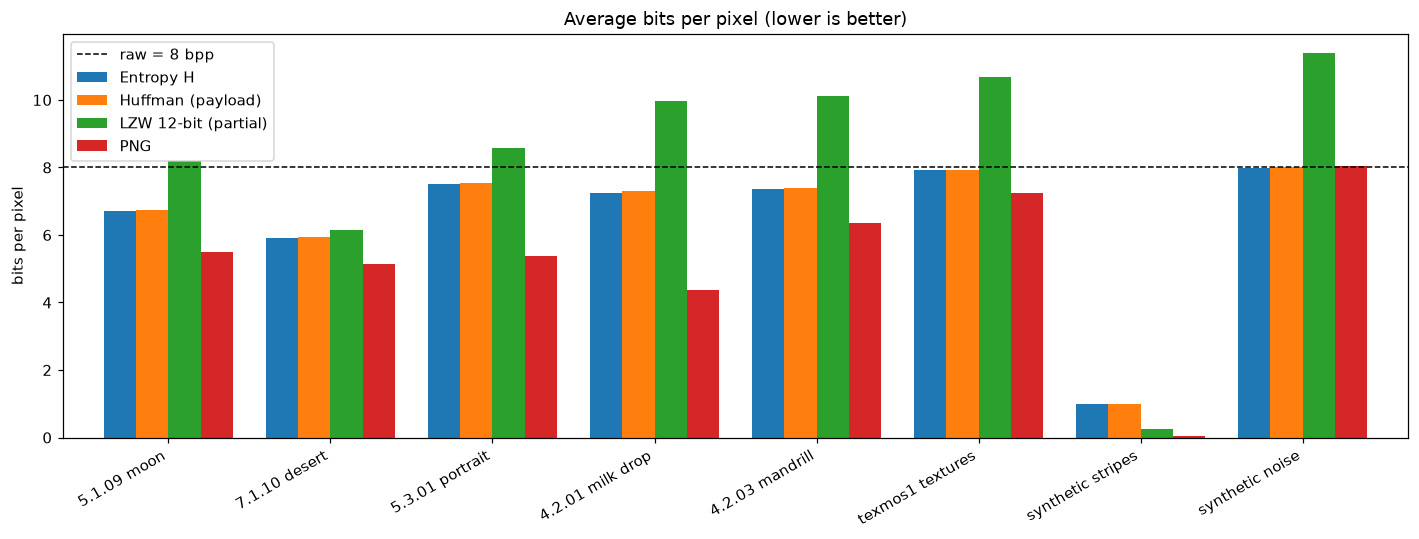

In [13]:
table = pd.DataFrame({k: {"Entropy H": v["H"], "Huffman (payload)": v["Huffman"],
                          "LZW 12-bit (partial)": v["LZW (12-bit)"], "PNG": v["PNG"]}
                      for k, v in results.items()}).T
print("Bits per pixel (raw = 8.000). Lower is better.")
display(table.round(3))
display((8 / table).round(2).rename(columns=lambda c: c + " ratio"))
table.round(4).to_csv(os.path.join(FIG_DIR, "week10_results.csv"))

ax = table.plot.bar(figsize=(13, 5), width=0.8)
ax.axhline(8, color="k", ls="--", lw=1, label="raw = 8 bpp")
ax.legend()
ax.set_ylabel("bits per pixel")
ax.set_title("Average bits per pixel (lower is better)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "week10_results.png"), bbox_inches="tight")
plt.show()

## 7. What we see, and what is left

**Observations from this run**

- **Huffman stays very close to the entropy** on every real image (within about 0.04 bits per pixel), as the theory says it must ($H \le L_{av} < H+1$). But both are only about 0.06 to 2.1 bits below the raw 8 bits, because most of these gray-value histograms are fairly spread out.
- **PNG is the best on every real image**, and it is even *below* the entropy on all of them. That is not a contradiction. The entropy computed here treats every pixel on its own, while PNG predicts each pixel from its neighbours, which exploits the fact that neighbouring pixels are similar. Neither Huffman nor LZW on raw pixel values can see that. We will test whether coding pixel *differences* closes the gap.
- **Fixed 12-bit LZW is worse than raw on five of the six real images.** Photographs rarely repeat long exact pixel sequences, so the phrases stay short, and 12 bits per code costs more than the 8 bits it replaces. Only the desert scene (the smoothest image) comes out below 8 bits. This matches Welch's own remark that noise-like data compresses poorly. LZW pays off clearly only on the repetitive synthetic stripes image.
- **Huffman cannot go below 1 bit per symbol.** On the stripes image (two values) Huffman needs exactly 1 bit per pixel, while LZW and PNG use far less. This is the whole-bit limit of Huffman coding.
- **Random noise is incompressible** for all methods. Entropy is about 8 bits, and LZW and PNG even add overhead.

**Not done yet**

1. Bit packing into real bytes, and the cost of the Huffman code table and file header.
2. Huffman decoder, and a round-trip check that decoded pixels equal the original.
3. LZW decoder (including the special case where the decoder receives a code it has not created yet), a proper table-full policy and variable code widths.
4. Reproducing one more result from the papers, for example Welch's compression ratios by data type.
5. Experiments on the effect of the main parameters (LZW code width and table size, Huffman on pixel differences) and the final comparison with PNG.